# Exercise 42 – Automatic differentiation of physical functions

**Week 8 · Automatic differentiation**

The same autograd trick applied to three functions: a Gaussian, a
Fermi–Dirac-like step, and the Lennard-Jones-Gauss pair potential, whose
derivative is (minus) the force between two atoms.

In [1]:
import matplotlib.pyplot as plt
import torch

from comphy.plotting import setup_axes
from comphy.potentials import LennardJonesGauss


def derivative(func, xs):
    """Evaluate ``func`` and its derivative on the grid ``xs``."""
    xs = xs.clone().requires_grad_(True)
    ys = func(xs)
    dydx = torch.autograd.grad(ys, xs, torch.ones_like(ys))[0]
    return xs.detach(), ys.detach(), dydx


def gaussian(x, A=3.0, x0=1.0, sigma=4.0):
    return A * torch.exp(-((x - x0) ** 2) / (2 * sigma**2))


def fermi_dirac(x, mu=-2.0, kT=3.0, g=2.0):
    return g / (torch.exp((x - mu) / kT) + 1)


lj_gauss = LennardJonesGauss(eps=2, r0=1.9)

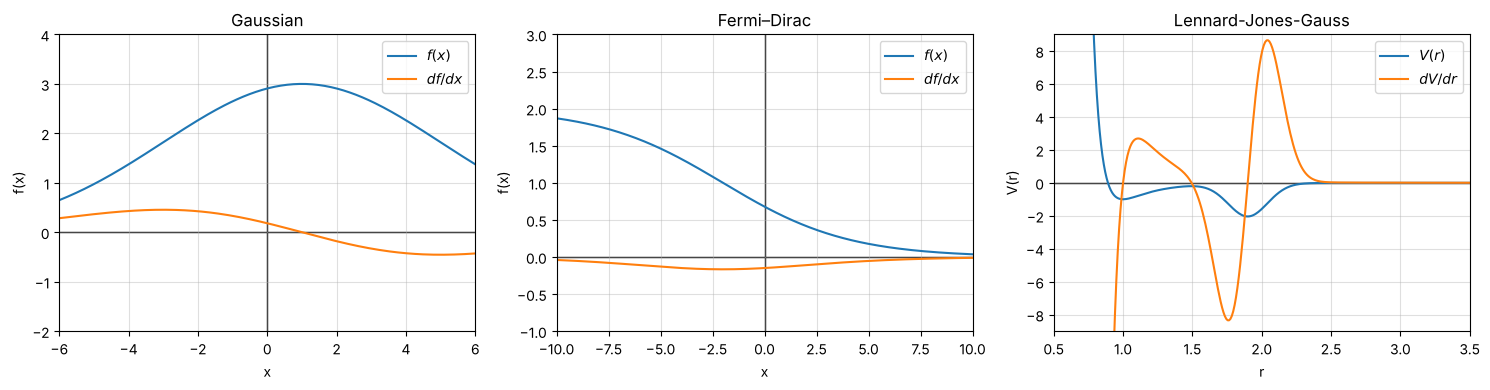

In [2]:
cases = [
    ("Gaussian", gaussian, torch.linspace(-6, 6, 200), (-6, 6), (-2, 4), "x", "f(x)"),
    ("Fermi–Dirac", fermi_dirac, torch.linspace(-10, 10, 200), (-10, 10), (-1, 3), "x", "f(x)"),
    ("Lennard-Jones-Gauss", lj_gauss.V, torch.linspace(0.5, 3.5, 300), (0.5, 3.5), (-9, 9), "r", "V(r)"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, func, grid, xlim, ylim, xlabel, ylabel) in zip(axes, cases):
    x, y, dy = derivative(func, grid)
    ax.plot(x, y, label=f"${ylabel}$")
    ax.plot(x, dy, label=f"$d{ylabel[0]}/d{xlabel}$")
    setup_axes(ax, xlim=xlim, ylim=ylim, xlabel=xlabel, ylabel=ylabel, title=name)
    ax.legend()
fig.tight_layout()
plt.show()

The derivative of the pair potential is zero at the two minima (the
Lennard-Jones minimum at $r = 1$ and the Gaussian well at $r = r_0$) and at
the barrier between them.